In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
## Load Dataset
df = pd.read_csv('students_scores.csv')
df.head()

,Student_ID,Age,Math_Score,Science_Score,English_Score,Hours_Studied,Pass_Fail
0,STU0001,17,70.46,87.56,53.95,2.0,0
1,STU0002,18,57.00,63.07,66.22,3.0,1
2,STU0003,16,60.41,84.00,54.00,8.0,0
3,STU0004,18,51.00,62.00,61.00,1.5,1
4,STU0005,18,64.63,54.78,78.56,5.0,0


In [3]:
df.shape

(5000, 7)

## 1: Measures of Central Tendency & Dispersion

#### 1.1 Mean, Median, Mode

In [4]:
df = pd.read_csv('students_scores.csv')

mean_value = df['Math_Score'].mean()
median_value = df['Math_Score'].median()
mode_value = stats.mode(df['Math_Score'],keepdims=False).mode

print(f"Math_Score -> Mean: {mean_value:.2f},  Median: {median_value:.2f},  Mode: {mode_value}")

Math_Score -> Mean: 68.18,  Median: 68.16,  Mode: 100.0


#### 1.2 Range, Variance, Standard Deviation of Science_Score

In [5]:
score_range = (df['Science_Score'].max() - df['Science_Score'].min())
variance = df['Science_Score'].var()
std_dev = df['Science_Score'].std()

print(f"Science_Score -> Range: {score_range:.2f},  Variance: {variance:.2f},  Std Dev: {std_dev:.2f}")

Science_Score -> Range: 80.00,  Variance: 213.16,  Std Dev: 14.60


## 2: Probability Basics

#### 2.1 Probability of passing

In [6]:
pass_count = (df['Pass_Fail'] == 1).sum()
total_students = len(df)

p_pass = pass_count / total_students

print("Pass Students:", pass_count)
print("Total Students:", total_students)
print(f"P(Pass_Fail = 1): {p_pass:.4f} ({p_pass * 100:.2f}%)")

Pass Students: 3054
Total Students: 5000
P(Pass_Fail = 1): 0.6108 (61.08%)


#### 2.2 Contingency table

In [7]:
df['Study_Group'] = np.where(
    df['Hours_Studied'] > 5,'More than 5 Hours','5 Hours or Less')

contingency_table = pd.crosstab(
    df['Study_Group'],df['Pass_Fail'])

print(contingency_table)

Pass_Fail             0     1
Study_Group                  
5 Hours or Less    1261  1156
More than 5 Hours   685  1898


#### 2.3 Conditional Probability

In [8]:
gt_5 = df[df["Hours_Studied"] > 5]
p_pass_given_gt5 = (gt_5["Pass_Fail"] == 1).mean()
print(f"P(Pass | Hours_Studied > 5): {p_pass_given_gt5:.4f} ({p_pass_given_gt5 * 100:.2f}%)")

P(Pass | Hours_Studied > 5): 0.7348 (73.48%)


## 3: Distribution & Visualization

#### 3.1 Histogram + Normal curve

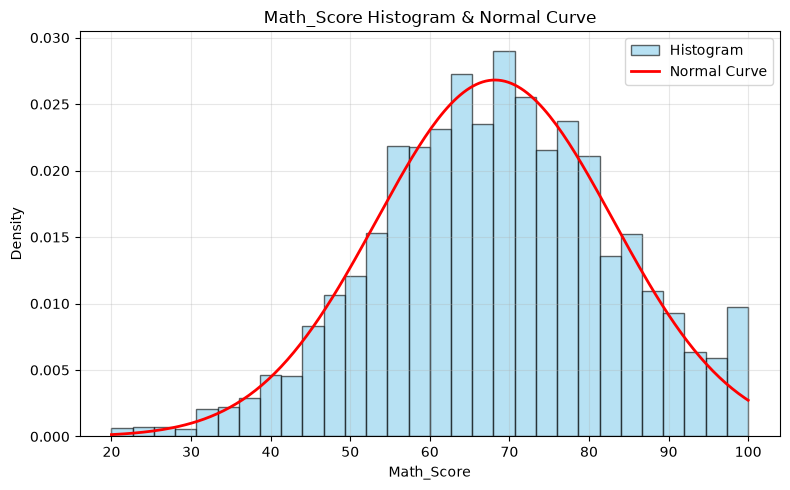


Interpretation: The histogram shows the distribution of students' Math scores. The normal curve helps us understand whether the scores follow an approximately normal distribution. Most scores are concentrated around the central range, while fewer students have very low or very high scores.


In [9]:
math_data = df["Math_Score"]
mu, sigma = math_data.mean(), math_data.std()

plt.figure(figsize=(8, 5))
count, bins, _ = plt.hist(math_data, bins=30, density=True, alpha=0.6, color="skyblue", edgecolor="black", label="Histogram")
x = np.linspace(math_data.min(), math_data.max(), 200)
plt.plot(x, stats.norm.pdf(x, mu, sigma), "r-", linewidth=2, label="Normal Curve")
plt.title("Math_Score Histogram & Normal Curve")
plt.xlabel("Math_Score")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/ Math_Histogram.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretation: The histogram shows the distribution of students' Math scores. The normal curve helps us understand whether the scores follow an approximately normal distribution. Most scores are concentrated around the central range, while fewer students have very low or very high scores.")

#### 3.2 Skewness & Kurtosis

In [10]:
sci_skew = stats.skew(df["Science_Score"])
sci_kurt_excess = stats.kurtosis(df["Science_Score"])
sci_kurt_pearson = stats.kurtosis(df["Science_Score"], fisher=False)
print(f"Science_Score -> Skewness: {sci_skew:.4f},  Excess Kurtosis: {sci_kurt_excess:.4f},  Pearson Kurtosis: {sci_kurt_pearson:.4f}")

## (Fisher kurtosis by default; excess=False gives Pearson kurtosis)

Science_Score -> Skewness: -0.0772,  Excess Kurtosis: -0.2913,  Pearson Kurtosis: 2.7087


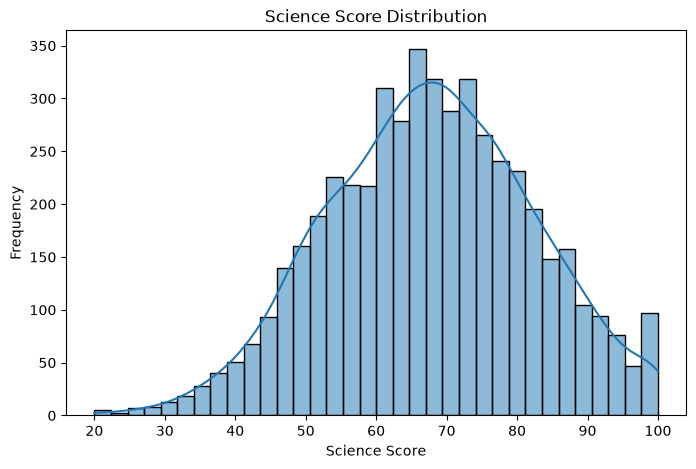


Interpretation: Skewness measures the symmetry of the Science scores distribution, while kurtosis measures the heaviness of the tails.


In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Science_Score'], kde=True)
plt.title('Science Score Distribution')
plt.xlabel('Science Score')
plt.ylabel('Frequency')
plt.savefig('images/ sci_skew_kurt.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretation: Skewness measures the symmetry of the Science scores distribution, while kurtosis measures the heaviness of the tails.")

#### 3.3 Q-Q Plot

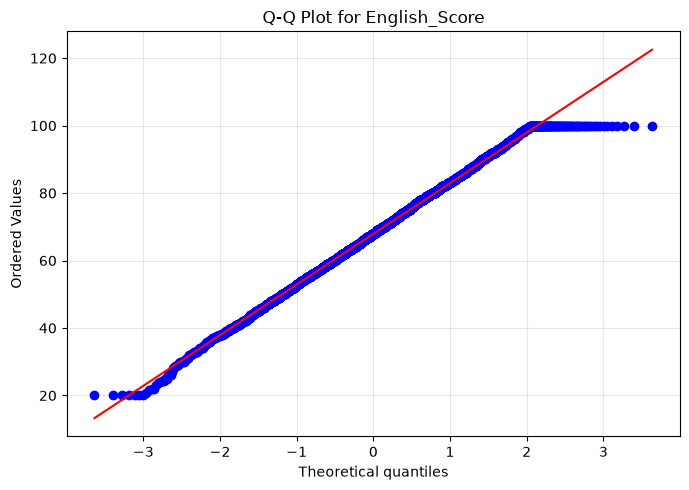


Interpretation: The Q-Q plot compares the English scores with a theoretical normal distribution. Most points lie close to the diagonal line, the data is approximately normally distributed. If points move away from the line, the data may not follow a normal distribution.


In [12]:
plt.figure(figsize=(7, 5))
stats.probplot(df["English_Score"], dist="norm", plot=plt)
plt.title("Q-Q Plot for English_Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/ QQ_Plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nInterpretation: The Q-Q plot compares the English scores with a theoretical normal distribution. Most points lie close to the diagonal line, the data is approximately normally distributed. If points move away from the line, the data may not follow a normal distribution.")

## 4: Linear Algebra

#### 4.1 Vectors of first 5 students

In [13]:
math_vector = df['Math_Score'].head(5).values
science_vector = df['Science_Score'].head(5).values

print("Math Vector (first 5):", math_vector)
print("Science Vector (first 5):", science_vector)

Math Vector (first 5): [70.46 57.   60.41 51.   64.63]
Science Vector (first 5): [87.56 63.07 84.   62.   54.78]


#### 4.2 Dot Product of the two vectors

In [14]:
dot_product = np.dot( math_vector,science_vector)
print(f"Dot Product: {dot_product:.4f}")

Dot Product: 21541.3390


#### 4.3 Norm 1 and Norm 2 of Math_Score vector

In [15]:
norm_1 = np.linalg.norm( math_vector,ord=1)
norm_2 = np.linalg.norm(math_vector,ord=2)

print(f"Norm 1 (L1) of Math_Score vector: {norm_1:.4f}")
print(f"Norm 2 (L2) of Math_Score vector: {norm_2:.4f}")

Norm 1 (L1) of Math_Score vector: 303.5000
Norm 2 (L2) of Math_Score vector: 136.5321


#### 4.4 Angle Between the Two Vectors

In [16]:
l2_norm_sci = np.linalg.norm(science_vector, ord=2)
cos_theta = np.clip(dot_product / (norm_2 * l2_norm_sci), -1.0, 1.0)
angle_rad = np.arccos(cos_theta)
angle_deg = np.degrees(angle_rad)
print(f"Angle between vectors: {angle_deg:.4f} degrees ({angle_rad:.4f} radians)")

Angle between vectors: 9.1966 degrees (0.1605 radians)


### 3 to 5 Bullet Insights

In [17]:
pass_percentage = df['Pass_Fail'].mean() * 100
fail_percentage = 100 - pass_percentage
avg_math = df['Math_Score'].mean()
avg_science = df['Science_Score'].mean()
avg_english = df['English_Score'].mean()
study_more = df[df['Hours_Studied'] > 5]
study_pass_percentage = (
    study_more['Pass_Fail'].mean() * 100)

print("KEY INSIGHTS")
print(f"1. Overall pass percentage is {pass_percentage:.2f}%.")
print(f"2. Overall fail percentage is {fail_percentage:.2f}%.")
print(f"3. Average Math Score is {avg_math:.2f}.")
print(f"4. Average Science Score is {avg_science:.2f}.")
print(f"5. Students studying more than 5 hours have "
      f"{study_pass_percentage:.2f}% pass rate.")

KEY INSIGHTS
1. Overall pass percentage is 61.08%.
2. Overall fail percentage is 38.92%.
3. Average Math Score is 68.18.
4. Average Science Score is 67.67.
5. Students studying more than 5 hours have 73.48% pass rate.
